# Tentativo 16 · 7. Analisi degli embedding

L'embedding **Qwen3-Embedding-8B congelato** con un modello lineare è il primo modello sopra il TF-IDF (notebook 6). Qui
proviamo a migliorarlo senza toccare il modello di embedding:
1. **il parametro del modello lineare scelto dentro il training**: nel notebook 4 C = 10 e alpha = 1 erano fissi;
2. **altri modi di mettere insieme**: un vettore per testata (la media dei suoi articoli) invece del voto degli
   articoli, la regressione **ordinale** (i livelli sono in ordine), e **TF-IDF + embedding** (la media delle due previsioni);
3. **un'altra istruzione** per l'embedding: sullo stile invece che sull'affidabilità.

**Regola**: ogni scelta si fa dentro il training di ogni fold, con una cross-validation interna sulle testate di
training (3 fold, testate mai divise); il fold di test non entra mai nella scelta. Stessi 5 fold di tutto il tentativo.

In [1]:
EMBEDDING = "Results/embedding/Qwen3-Embedding-8B"              # gli embedding del notebook 4 (istruzione sull'affidabilità)
ALTRA = "Results/embedding/Qwen3-Embedding-8B_stile"            # punto 3: gli stessi con l'istruzione sullo stile
INTERNI = 3                                                     # fold della cross-validation interna
N_JOBS = 32

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import funzioni as F

warnings.filterwarnings("ignore")
OUT = Path("Results/analisi_embedding"); OUT.mkdir(parents=True, exist_ok=True)
art = pd.read_csv(F.DATASET / "articoli.csv.gz")
t = pd.read_csv(F.DATASET / "testate.csv", index_col="domain")


def leggi(cartella):
    """Gli embedding salvati dal notebook 4, se ci sono e sono di questo dataset."""
    f, f_id = Path(cartella) / "embedding.npy", Path(cartella) / "embedding_article_id.npy"
    if f.exists() and f_id.exists() and np.array_equal(np.load(f_id), art.article_id.to_numpy()):
        return np.load(f)


def calcola(nome, funzione):
    """Le previsioni e la griglia di una variante: si calcolano una volta, poi si rileggono."""
    f, g = OUT / f"{nome}_previsioni.csv", OUT / f"{nome}_griglia.csv"
    if not (f.exists() and g.exists()):
        pa, griglia = funzione(); pa.to_csv(f, index=False); griglia.to_csv(g, index=False)
    return pd.read_csv(f), pd.read_csv(g)


E = leggi(EMBEDDING)
T = {"TF-IDF": pd.read_csv("Results/feature/previsioni_testate.csv", index_col=0),
     "8B come nel notebook 4 (C=10, alpha=1)": pd.read_csv(Path(EMBEDDING) / "previsioni_testate.csv", index_col=0)}
print(f"{len(art):,} articoli di {len(t)} testate · embedding {E.shape[1]} dimensioni")

25,524 articoli di 226 testate · embedding 4096 dimensioni


## 1. Il parametro scelto dentro il training

Per ogni fold, la cross-validation interna prova cinque valori: C della logistica (5 classi) da 0,001 a 10, alpha della
ridge (regressione) da 1 a 10.000. Criterio: F1 sui 5 livelli delle testate di validazione (voto degli articoli) per la
logistica, correlazione di Spearman tra punteggio vero e medio previsto per la ridge. Poi il modello si riaddestra su
tutto il training con il valore migliore. Circa 15 minuti la prima volta.

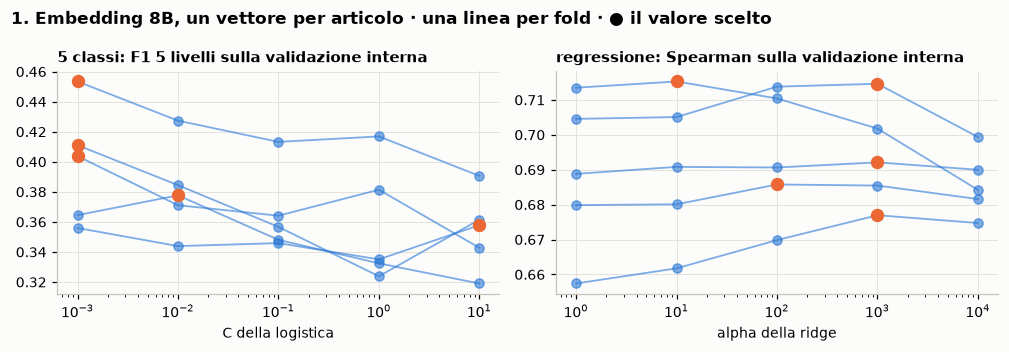

In [3]:
pa1, g1 = calcola("articoli", lambda: F.modelli_scelti(E, art, interni=INTERNI, n_jobs=N_JOBS))
F.grafico_griglia(g1, "1. Embedding 8B, un vettore per articolo", OUT / "griglia_articoli.png")
T["8B, parametro scelto"] = F.testate_da_previsioni(pa1, t)

## 2. Altri modi di mettere insieme

- **Un vettore per testata**: la media dei vettori dei suoi articoli; il modello lineare impara sulle testate (circa
  180 per fold) invece che sugli articoli, quindi niente voto. Tre modelli: 5 classi, **ordinale** (quattro logistiche
  «livello ≥ l2», «≥ l3»…, Frank e Hall 2001) e regressione, ognuno con il parametro scelto come al punto 1.
- **TF-IDF + 8B**: per ogni articolo la media delle probabilità (5 classi) o dei punteggi (regressione) del TF-IDF del
  notebook 3 e dell'8B del punto 1, con pesi uguali fissati prima (nessuna scelta sul test).

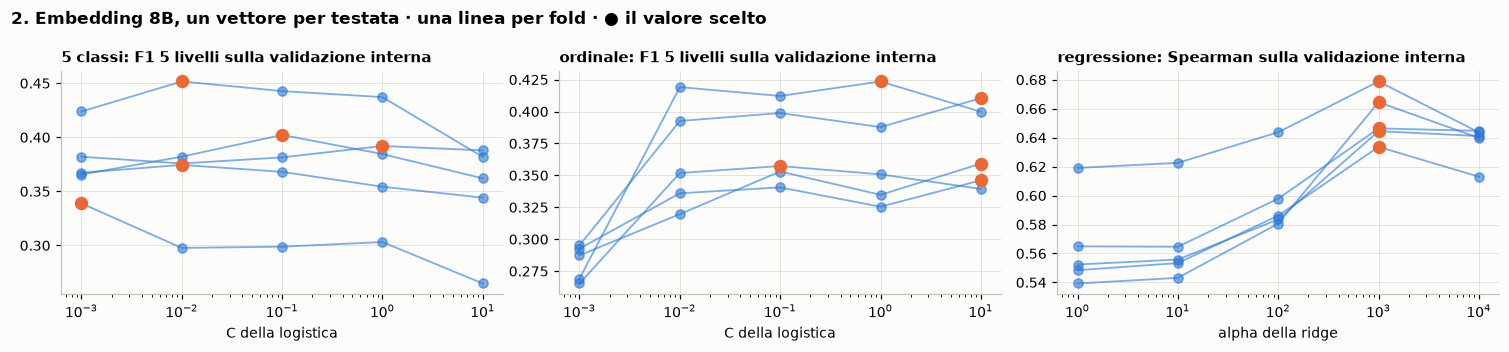

In [4]:
M, righe = F.media_per_testata(E, art)
pa2, g2 = calcola("testate", lambda: F.modelli_scelti(M, righe, tipi=("5 classi", "ordinale", "regressione"), interni=INTERNI, n_jobs=N_JOBS))
F.grafico_griglia(g2, "2. Embedding 8B, un vettore per testata", OUT / "griglia_testate.png")
T["8B, un vettore per testata"] = F.testate_da_previsioni(pa2, t)
T["8B, un vettore per testata, ordinale"] = F.testate_da_previsioni(pa2, t, ordinale=True)

tfidf = pd.read_csv("Results/feature/previsioni_articoli.csv").set_index("article_id")
insieme = pa1.set_index("article_id")
colonne = F.CLASSI + ["s_regressione"]
insieme[colonne] = (insieme[colonne] + tfidf.loc[insieme.index, colonne]) / 2
T["TF-IDF + 8B (media)"] = F.testate_da_previsioni(insieme.reset_index(), t)

## 3. Un'altra istruzione

Qwen3-Embedding legge l'articolo preceduto da un'istruzione che dice a che cosa serve il vettore. Nel notebook 4:
*"Represent this news article to judge the reliability and journalistic standards of the outlet that published it"*.
Qui: *"Represent the writing style, tone, sourcing and rigor of this news article, regardless of its topic"*, per
spingere il vettore verso **come** è scritto l'articolo invece che **di che cosa** parla. Gli embedding si calcolano con il
notebook 4 (`ETICHETTA = "stile"`, circa 2 ore di GPU); sopra, gli stessi modelli dei punti 1 e 2.

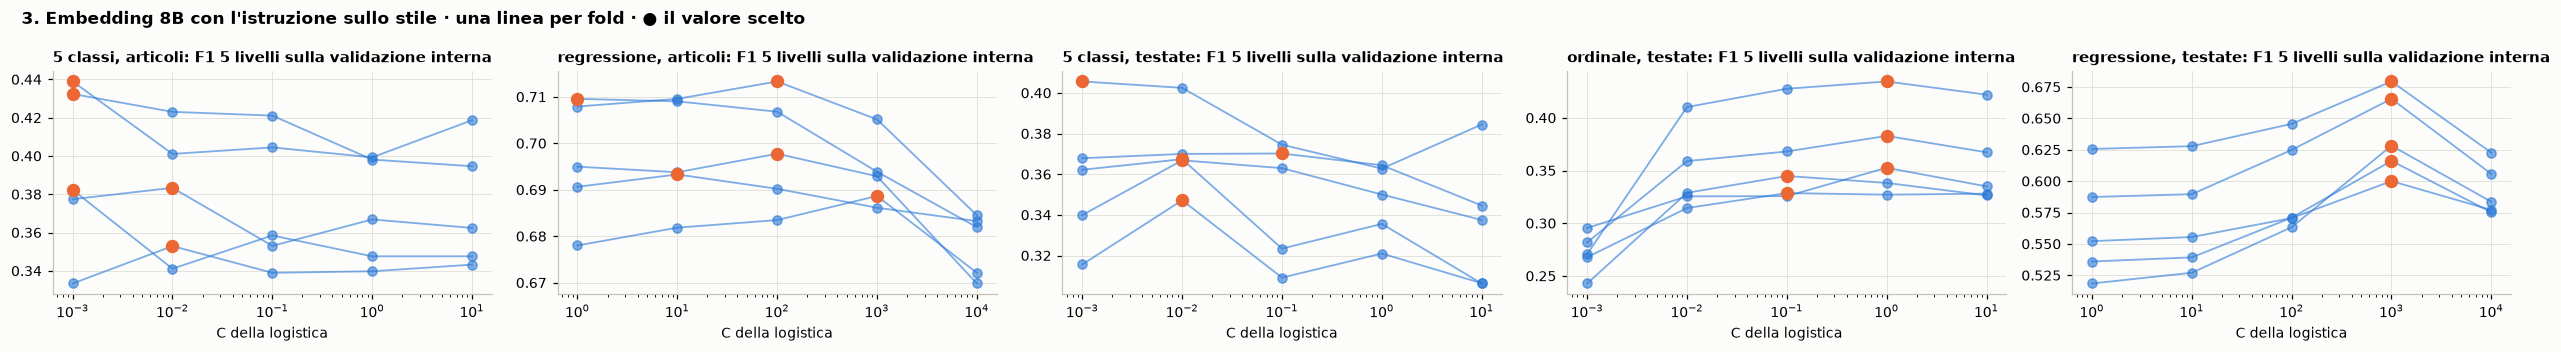

In [5]:
E2 = leggi(ALTRA)
if E2 is None:
    print("gli embedding con l'istruzione sullo stile non ci sono ancora")
else:
    T["8B «stile» come nel notebook 4 (C=10, alpha=1)"] = pd.read_csv(Path(ALTRA) / "previsioni_testate.csv", index_col=0)
    pa3, g3 = calcola("stile_articoli", lambda: F.modelli_scelti(E2, art, interni=INTERNI, n_jobs=N_JOBS))
    T["8B «stile», parametro scelto"] = F.testate_da_previsioni(pa3, t)
    M2, _ = F.media_per_testata(E2, art)
    pa4, g4 = calcola("stile_testate", lambda: F.modelli_scelti(M2, righe, tipi=("5 classi", "ordinale", "regressione"), interni=INTERNI, n_jobs=N_JOBS))
    T["8B «stile», un vettore per testata"] = F.testate_da_previsioni(pa4, t)
    T["8B «stile», un vettore per testata, ordinale"] = F.testate_da_previsioni(pa4, t, ordinale=True)
    F.grafico_griglia(pd.concat([g3.assign(tipo=g3.tipo + ", articoli"), g4.assign(tipo=g4.tipo + ", testate")]),
                      "3. Embedding 8B con l'istruzione sullo stile", OUT / "griglia_stile.png")

## 3 bis. Un LLM grande come lettore: Mistral-Small 24B

Non esistono modelli di embedding aperti più grandi di 8B, quindi il modello più grande è un **LLM generativo**,
Mistral-Small 24B, congelato e in 4 bit (notebook 8): ogni articolo è la media degli stati nascosti dei suoi token, allo
strato 27 di 40 (circa due terzi) e all'ultimo. Sopra, gli stessi modelli dei punti 1 e 2: il parametro scelto nel training
e un vettore per testata, come classificatore (5 classi) e come regressore.

/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.349425601432813e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.80347014281324e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.405699165019541e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.629731157976494e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.618550768029309e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


...

/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.578363891980189e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.195355067324272e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 8.088321123977948e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.534399770747768e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.983064082533019e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


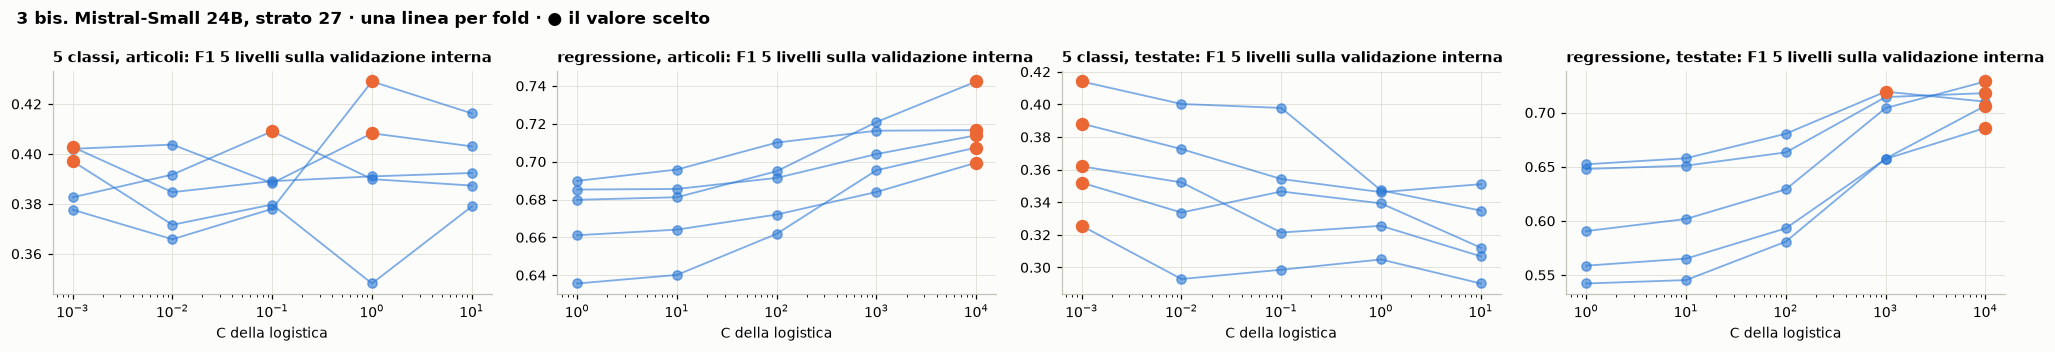

/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 4.324479974116002e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.5725292946153786e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.0327961064149349e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.0063419608741242e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.910432511133877e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


...

/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 9.962858626977322e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.84295724131789e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 9.727887828603343e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.5152680766259436e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 9.721946980789653e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.710723461836096e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


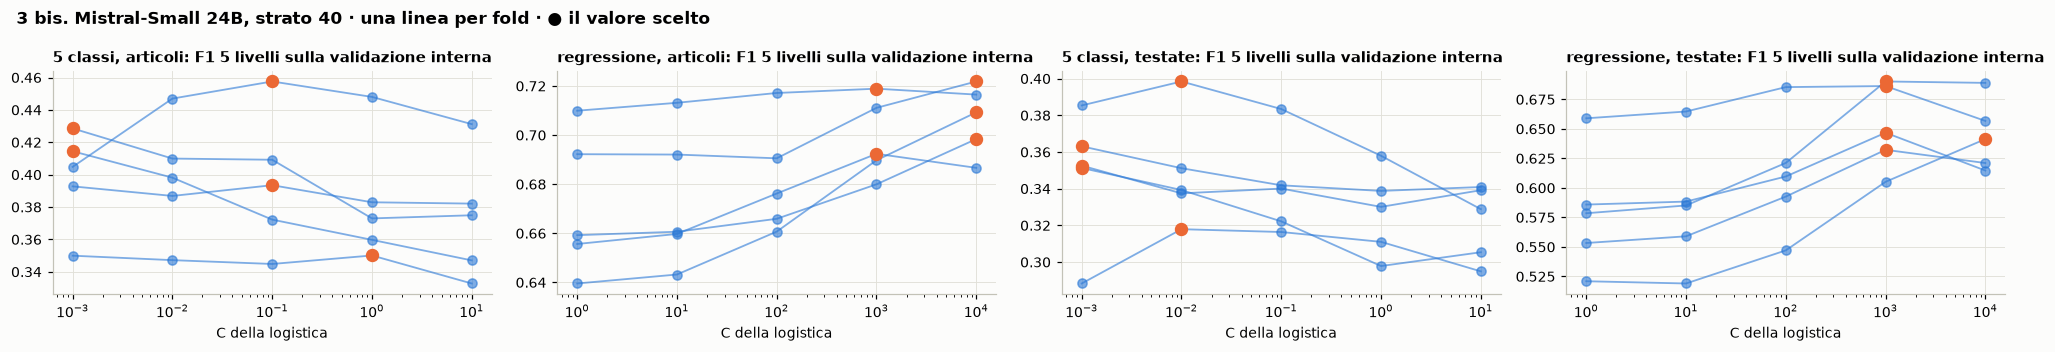

In [6]:
MISTRAL, STRATI_MISTRAL = "Results/embedding/Mistral-Small-24B-Base-2501_strato{s}", [27, 40]
for s in STRATI_MISTRAL:
    Em = leggi(MISTRAL.format(s=s))
    if Em is None:
        print(f"i vettori di Mistral (strato {s}) non ci sono ancora: vanno calcolati con il notebook 8"); continue
    T[f"Mistral 24B, strato {s}, come nel notebook 8 (C=10, alpha=1)"] = pd.read_csv(Path(MISTRAL.format(s=s)) / "previsioni_testate.csv", index_col=0)
    pam, gm = calcola(f"mistral{s}_articoli", lambda: F.modelli_scelti(Em, art, interni=INTERNI, n_jobs=N_JOBS))
    T[f"Mistral 24B, strato {s}, parametro scelto"] = F.testate_da_previsioni(pam, t)
    Mm, _ = F.media_per_testata(Em, art)
    pbm, gbm = calcola(f"mistral{s}_testate", lambda: F.modelli_scelti(Mm, righe, interni=INTERNI, n_jobs=N_JOBS))
    T[f"Mistral 24B, strato {s}, un vettore per testata"] = F.testate_da_previsioni(pbm, t)
    F.grafico_griglia(pd.concat([gm.assign(tipo=gm.tipo + ", articoli"), gbm.assign(tipo=gbm.tipo + ", testate")]),
                      f"3 bis. Mistral-Small 24B, strato {s}", OUT / f"griglia_mistral{s}.png")

## 4. Tutti i risultati insieme

Qui ci sono anche i modelli dei notebook 3–5, per avere tutto in un posto solo:

| nel grafico | che cos'è |
|---|---|
| TF-IDF | parole e coppie di parole, logistica/ridge (notebook 3): il riferimento |
| ModernBERT | ModernBERT-base addestrato, 5 epoche, articoli interi (notebook 5) |
| Qwen3 0,6B / 8B | embedding congelati con l'istruzione sull'affidabilità, C = 10 e alpha = 1 fissi (notebook 4) |
| parametro scelto | come sopra, ma C e alpha scelti dentro il training (punto 1) |
| un vettore per testata | la media dei vettori degli articoli, il modello impara sulle testate (punto 2) |
| ordinale | come sopra, con la regressione ordinale invece delle 5 classi (punto 2) |
| TF-IDF + 8B | la media delle previsioni dei due modelli (punto 2) |
| «stile» | gli stessi modelli 8B con l'istruzione sullo stile (punto 3) |
| Mistral 24B | l'LLM grande come lettore, strato 27 o 40, con C = 10 e alpha = 1 fissi (notebook 8), con il parametro scelto o con un vettore per testata (punto 3 bis) |

Le misure sono quelle del notebook 6: **F1** sui 5 livelli, **tolerant ±1** (giusto o sbagliato di un livello),
**affidabile sì/no** (punteggio ≥ 60) su tutte le testate e solo su l1–l2 contro l4–l5. In blu la classificazione a 5
classi, in arancio la regressione sul punteggio; linee grigie: intervalli al 95% (bootstrap sulle testate).

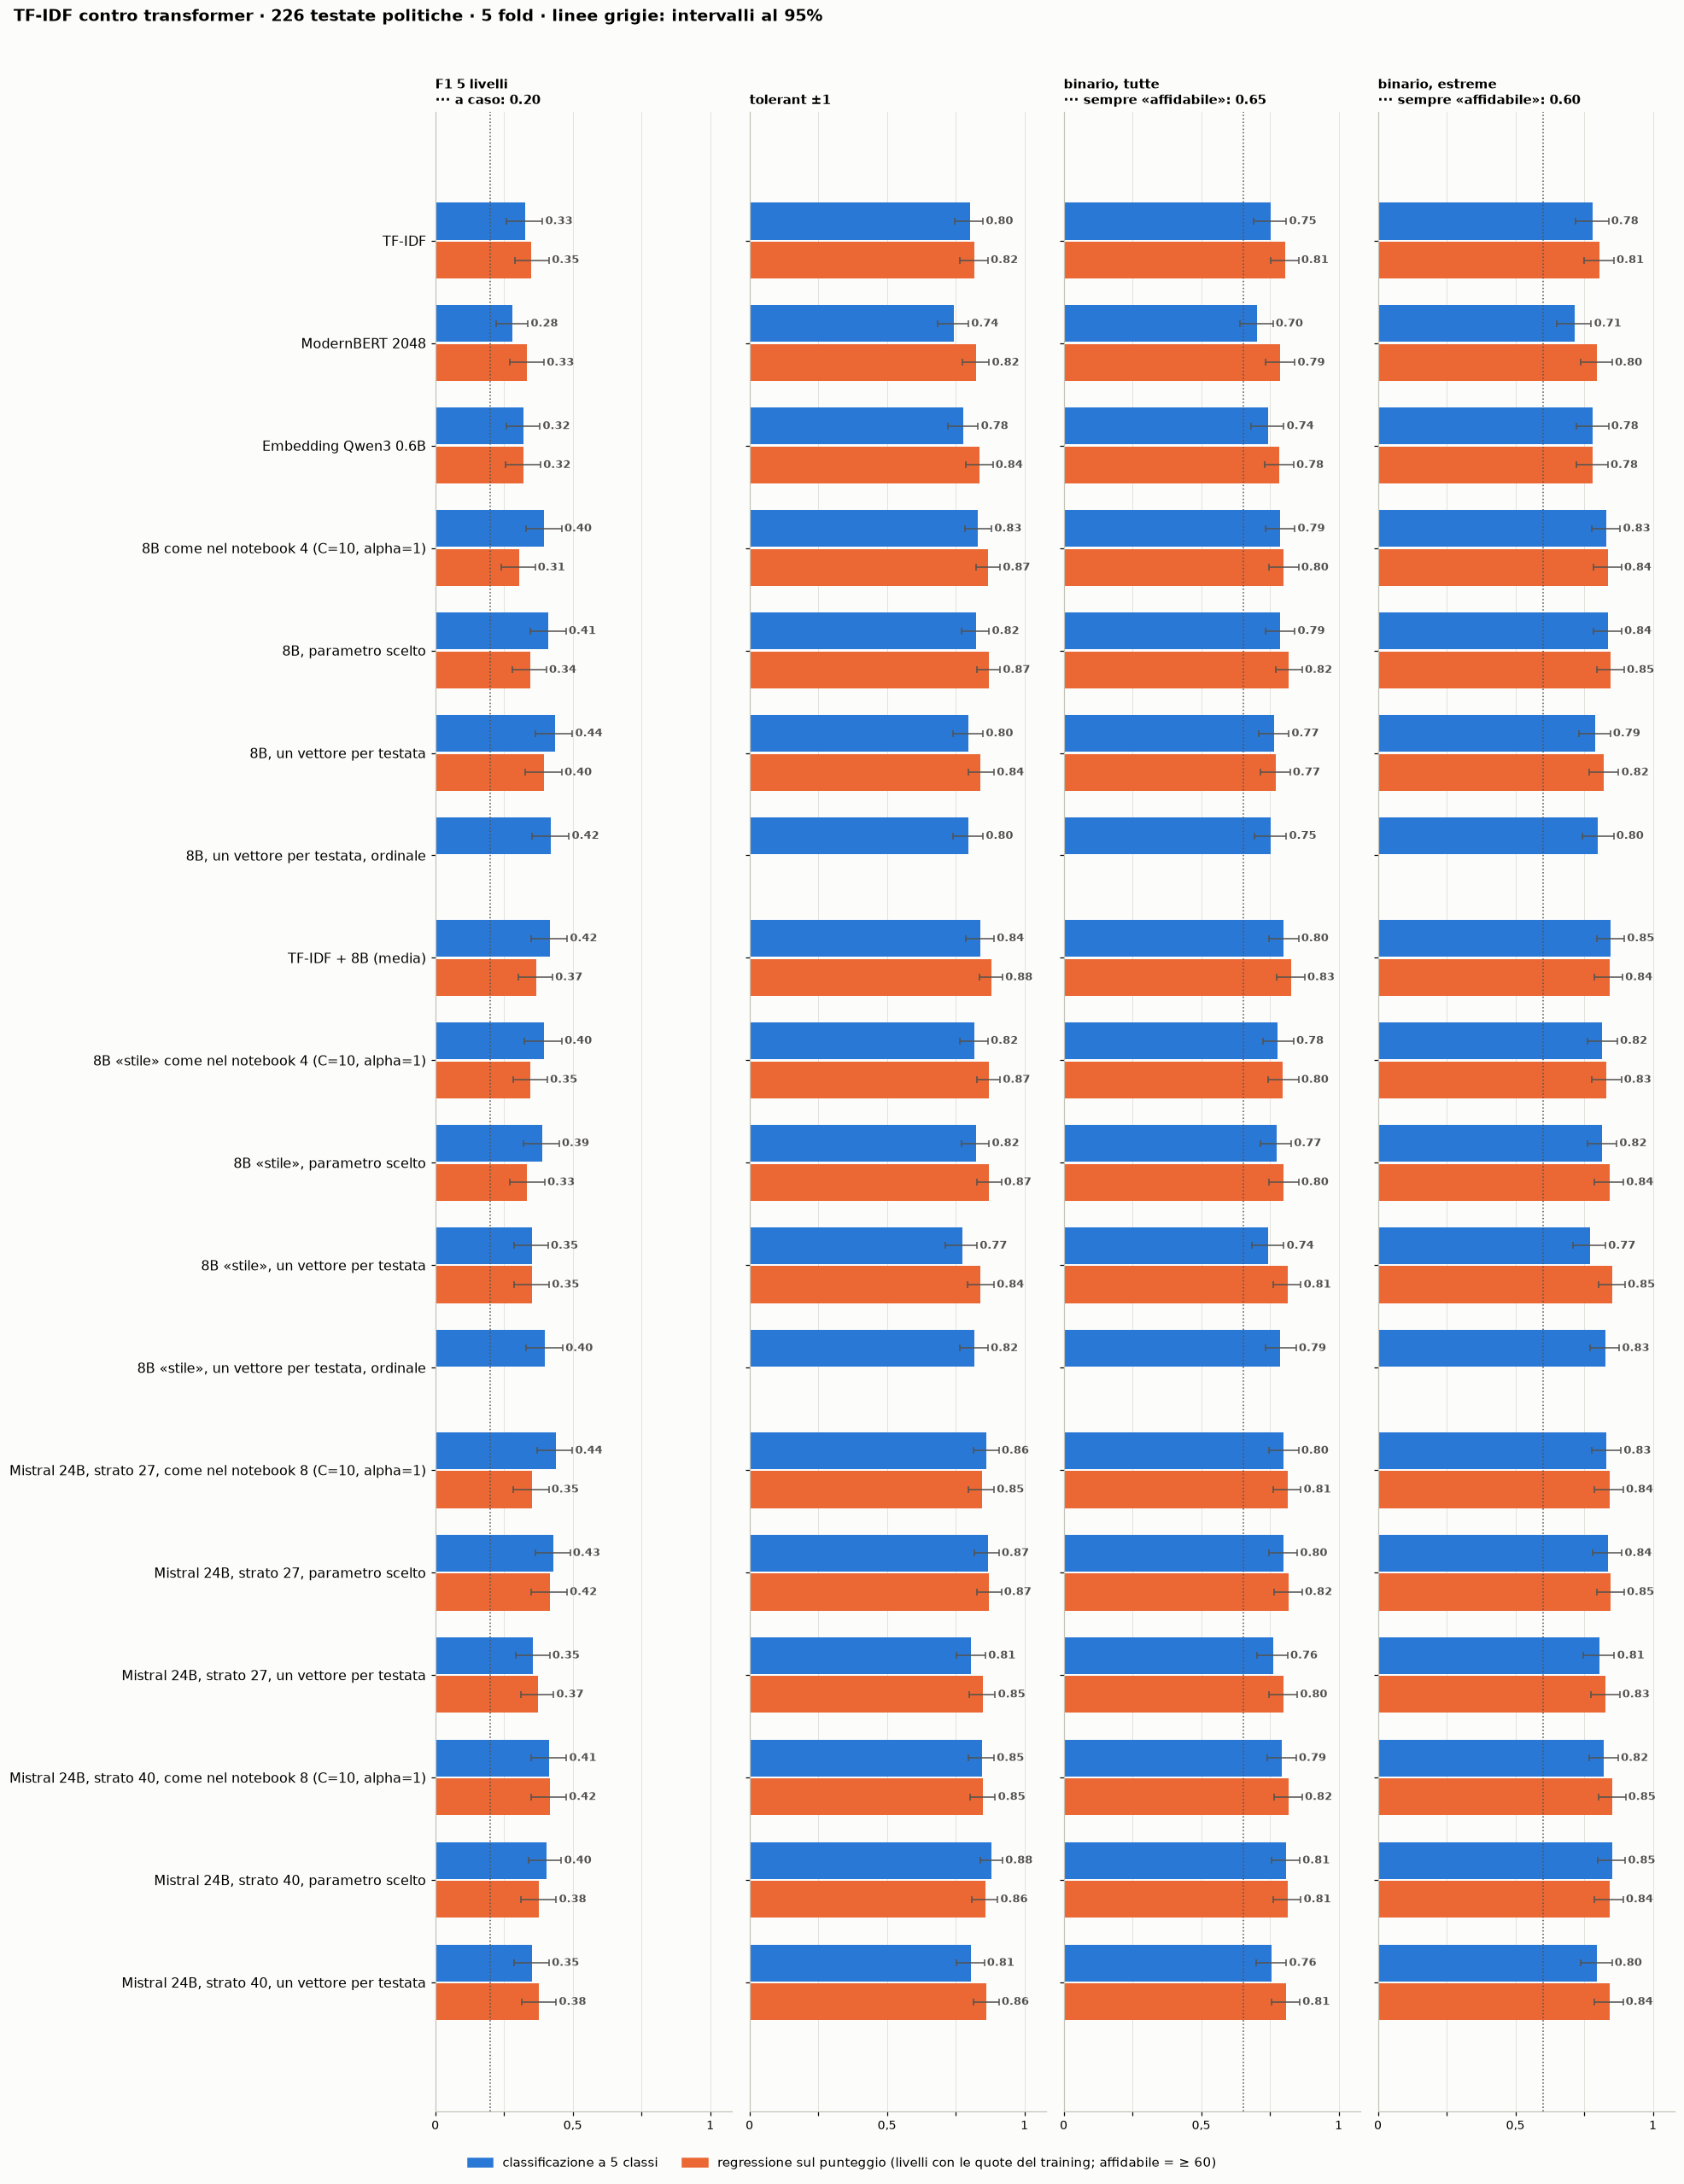

In [7]:
TUTTI = {"TF-IDF": T["TF-IDF"],
         "ModernBERT 2048": pd.read_csv("Results/modernbert/previsioni_testate.csv", index_col=0),
         "Embedding Qwen3 0.6B": pd.read_csv("Results/embedding/Qwen3-Embedding-0.6B/previsioni_testate.csv", index_col=0)}
TUTTI.update({nome: v for nome, v in T.items() if nome != "TF-IDF"})
AFF, STI = "istruzione sull'affidabilità", "istruzione sullo stile"
DESCRIZIONI = {
    "TF-IDF": "TF-IDF\nparole e coppie di parole\n+ logistica / ridge (C=10, alpha=1)",
    "ModernBERT 2048": "ModernBERT-base, addestrato\n5 epoche · lr 3e-5\narticoli interi (2.048 token)",
    "Embedding Qwen3 0.6B": f"Qwen3-Embedding 0,6B congelato\n{AFF}\n+ logistica / ridge (C=10, alpha=1)",
    "8B come nel notebook 4 (C=10, alpha=1)": f"Qwen3-Embedding 8B congelato\n{AFF}\n+ logistica / ridge (C=10, alpha=1)",
    "8B, parametro scelto": f"Qwen3 8B, {AFF}\nun vettore per articolo\nC e alpha scelti nel training",
    "8B, un vettore per testata": f"Qwen3 8B, {AFF}\nun vettore per testata (media)\nC e alpha scelti nel training",
    "8B, un vettore per testata, ordinale": f"Qwen3 8B, {AFF}\nun vettore per testata\nregressione ordinale, C scelto",
    "TF-IDF + 8B (media)": "TF-IDF + Qwen3 8B (parametro scelto)\nmedia delle due previsioni\nper ogni articolo",
    "8B «stile» come nel notebook 4 (C=10, alpha=1)": f"Qwen3-Embedding 8B congelato\n{STI}\n+ logistica / ridge (C=10, alpha=1)",
    "8B «stile», parametro scelto": f"Qwen3 8B, {STI}\nun vettore per articolo\nC e alpha scelti nel training",
    "8B «stile», un vettore per testata": f"Qwen3 8B, {STI}\nun vettore per testata (media)\nC e alpha scelti nel training",
    "8B «stile», un vettore per testata, ordinale": f"Qwen3 8B, {STI}\nun vettore per testata\nregressione ordinale, C scelto"}
for s in [27, 40]:
    DESCRIZIONI[f"Mistral 24B, strato {s}, come nel notebook 8 (C=10, alpha=1)"] = f"Mistral-Small 24B (LLM) congelato, 4 bit\nmedia dello strato {s} di 40\n+ logistica / ridge (C=10, alpha=1)"
    DESCRIZIONI[f"Mistral 24B, strato {s}, parametro scelto"] = f"Mistral-Small 24B, strato {s} di 40\nun vettore per articolo\nC e alpha scelti nel training"
    DESCRIZIONI[f"Mistral 24B, strato {s}, un vettore per testata"] = f"Mistral-Small 24B, strato {s} di 40\nun vettore per testata (media)\nC e alpha scelti nel training"
NOTA = ("Addestramento: sui 4 fold di training, tutte le testate (l1…l5, anche le l3). Test: le testate del fold escluso, "
        "una previsione per testata (voto o media dei suoi articoli; con «un vettore per testata»\nla previsione è già per "
        "testata). «Scelti nel training»: con una cross-validation interna alle testate di training, senza guardare il test. "
        "Baseline: chi risponde sempre allo stesso modo, senza leggere i testi.")
valori, intervalli, differenze, vero = F.misure_modelli(TUTTI)
valori.to_csv(OUT / "confronto.csv")
F.grafico_confronto(valori, intervalli, vero, OUT / "confronto.png")

### Lo stesso grafico, con i dettagli
Accanto ai nomi che cosa è ogni modello, nei titoli su quali testate si misura, sotto come si addestra e come si testa.

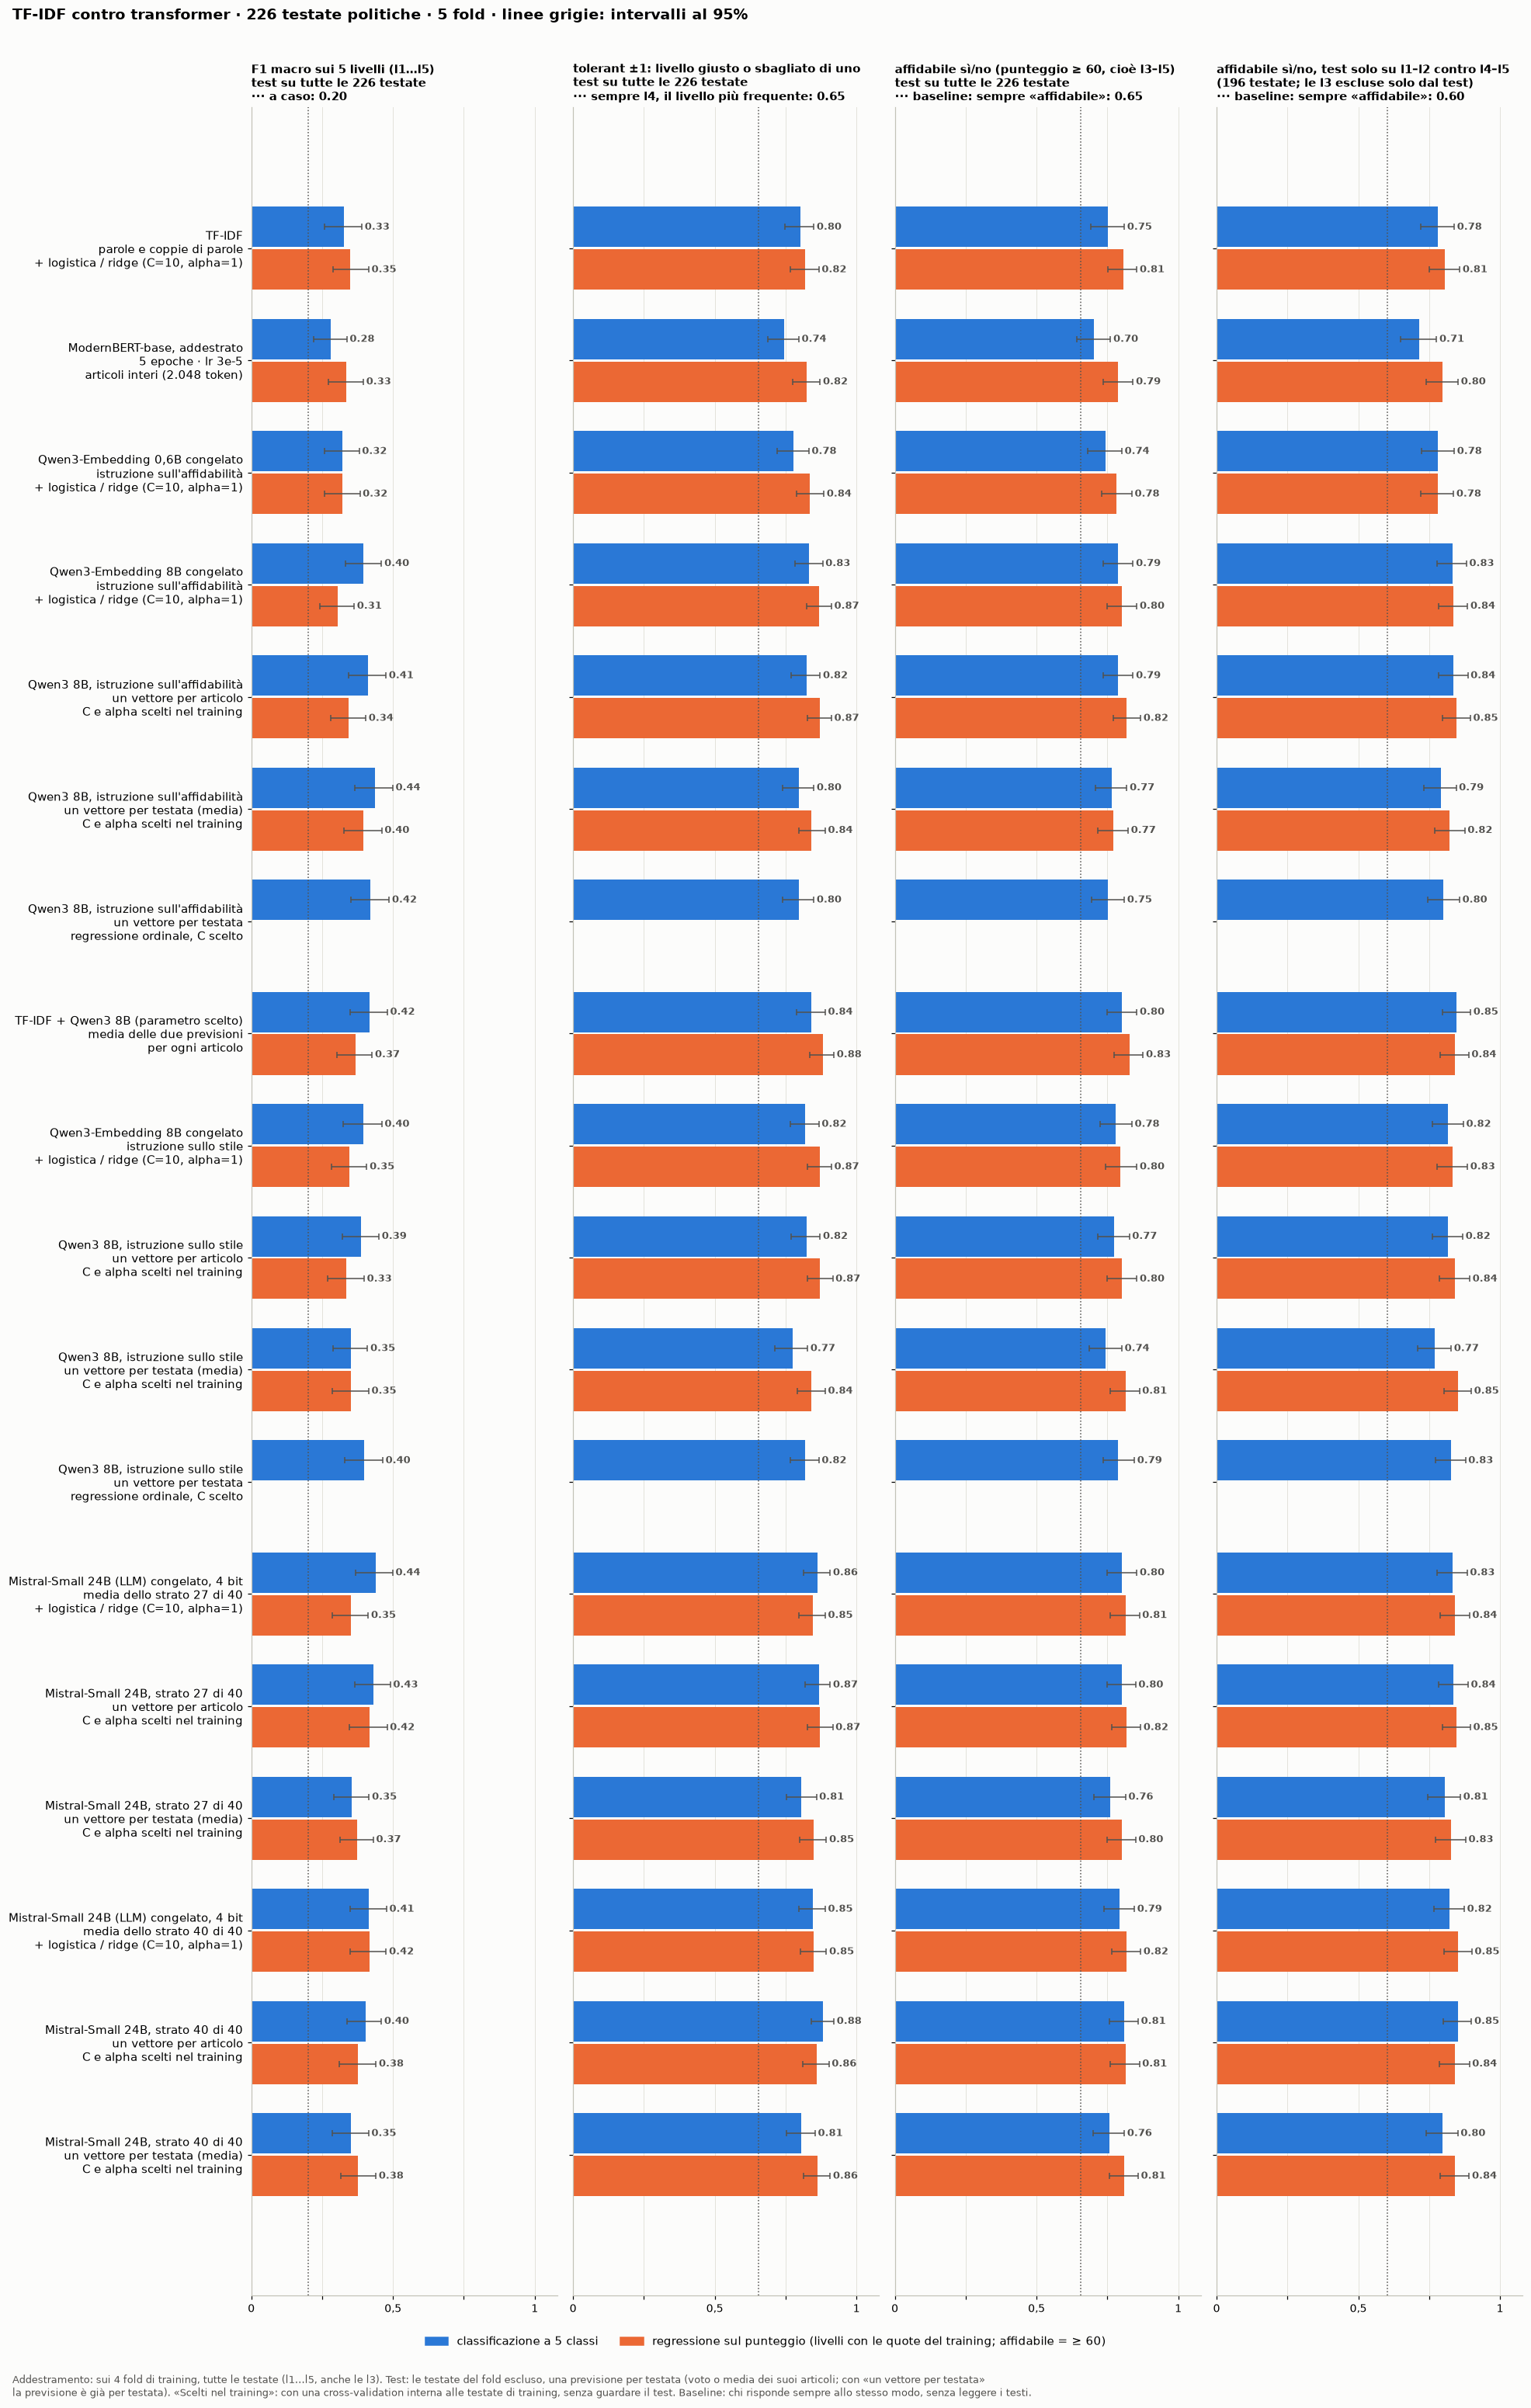

In [8]:
F.grafico_confronto(valori, intervalli, vero, OUT / "confronto_dettagli.png", dettagli=True, descrizioni=DESCRIZIONI, nota=NOTA)

### In numeri
In alto i valori; sotto la differenza da TF-IDF con la stessa impostazione (è chiara se l'intervallo non contiene lo zero).

In [9]:
display(valori.round(3))
differenze

F1 5 livelli  \
TF-IDF                                             5 classi            0.327   
                                                   regressione         0.349   
ModernBERT 2048                                    5 classi            0.281   
                                                   regressione         0.334   
Embedding Qwen3 0.6B                               5 classi            0.322   
                                                   regressione         0.321   
8B come nel notebook 4 (C=10, alpha=1)             5 classi            0.397   
                                                   regressione         0.305   
8B, parametro scelto                               5 classi            0.411   
                                                   regressione         0.344   
8B, un vettore per testata                         5 classi            0.436   
                                                   regressione         0.397   
8B, un vettore per testata, ordinale               5 classi            0.421   
TF-IDF + 8B (media)                                5 classi            0.417   
                                                   regressione         0.368   
8B «stile» come nel notebook 4 (C=10, alpha=1)     5 classi            0.395   
                                                   regressione         0.347   
8B «stile», parametro scelto                       5 classi            0.388   
                                                   regressione         0.334   
8B «stile», un vettore per testata                 5 classi            0.351   
                                                   regressione         0.353   
8B «stile», un vettore per testata, ordinale       5 classi            0.397   
Mistral 24B, strato 27, come nel notebook 8 (C=... 5 classi            0.438   
                                                   regressione         0.351   
Mistral 24B, strato 27, parametro scelto           5 classi            0.431   
                                                   regressione         0.416   
Mistral 24B, strato 27, un vettore per testata     5 classi            0.355   
                                                   regressione         0.374   
Mistral 24B, strato 40, come nel notebook 8 (C=... 5 classi            0.414   
                                                   regressione         0.417   
Mistral 24B, strato 40, parametro scelto           5 classi            0.403   
                                                   regressione         0.377   
Mistral 24B, strato 40, un vettore per testata     5 classi            0.351   
                                                   regressione         0.377   

                                                                tolerant ±1  \
TF-IDF                                             5 classi           0.801   
                                                   regressione        0.819   
ModernBERT 2048                                    5 classi           0.743   
                                                   regressione        0.823   
Embedding Qwen3 0.6B                               5 classi           0.779   
                                                   regressione        0.836   
8B come nel notebook 4 (C=10, alpha=1)             5 classi           0.832   
                                                   regressione        0.867   
8B, parametro scelto                               5 classi           0.823   
                                                   regressione        0.872   
8B, un vettore per testata                         5 classi           0.796   
                                                   regressione        0.841   
8B, un vettore per testata, ordinale               5 classi           0.796   
TF-IDF + 8B (media)                                5 classi           0.841   
                                                   regressione        0.881   

Δ F1 5 livelli dal TF-IDF  \
ModernBERT 2048                                    5 classi      -0.046 [-0.123; +0.029]   
                                                   regressione   -0.015 [-0.092; +0.062]   
Embedding Qwen3 0.6B                               5 classi      -0.005 [-0.068; +0.062]   
                                                   regressione   -0.028 [-0.099; +0.040]   
8B come nel notebook 4 (C=10, alpha=1)             5 classi      +0.069 [-0.000; +0.141]   
                                                   regressione   -0.044 [-0.128; +0.033]   
8B, parametro scelto                               5 classi      +0.084 [+0.019; +0.154]   
                                                   regressione   -0.005 [-0.080; +0.070]   
8B, un vettore per testata                         5 classi      +0.109 [+0.030; +0.187]   
                                                   regressione   +0.048 [-0.034; +0.124]   
8B, un vettore per testata, ordinale               5 classi      +0.094 [+0.015; +0.174]   
TF-IDF + 8B (media)                                5 classi      +0.090 [+0.037; +0.146]   
                                                   regressione   +0.019 [-0.051; +0.086]   
8B «stile» come nel notebook 4 (C=10, alpha=1)     5 classi      +0.068 [+0.001; +0.134]   
                                                   regressione   -0.002 [-0.076; +0.071]   
8B «stile», parametro scelto                       5 classi      +0.061 [-0.009; +0.135]   
                                                   regressione   -0.015 [-0.091; +0.063]   
8B «stile», un vettore per testata                 5 classi      +0.024 [-0.050; +0.094]   
                                                   regressione   +0.004 [-0.079; +0.076]   
8B «stile», un vettore per testata, ordinale       5 classi      +0.070 [-0.006; +0.143]   
Mistral 24B, strato 27, come nel notebook 8 (C=... 5 classi      +0.111 [+0.040; +0.182]   
                                                   regressione   +0.003 [-0.076; +0.078]   
Mistral 24B, strato 27, parametro scelto           5 classi      +0.103 [+0.033; +0.169]   
                                                   regressione   +0.067 [-0.005; +0.132]   
Mistral 24B, strato 27, un vettore per testata     5 classi      +0.027 [-0.040; +0.095]   
                                                   regressione   +0.025 [-0.040; +0.088]   
Mistral 24B, strato 40, come nel notebook 8 (C=... 5 classi      +0.087 [+0.019; +0.153]   
                                                   regressione   +0.068 [-0.006; +0.140]   
Mistral 24B, strato 40, parametro scelto           5 classi      +0.076 [+0.013; +0.138]   
                                                   regressione   +0.028 [-0.048; +0.101]   
Mistral 24B, strato 40, un vettore per testata     5 classi      +0.024 [-0.051; +0.101]   
                                                   regressione   +0.028 [-0.048; +0.103]   

                                                               Δ binario, tutte dal TF-IDF  
ModernBERT 2048                                    5 classi        -0.049 [-0.111; +0.009]  
                                                   regressione     -0.018 [-0.058; +0.022]  
Embedding Qwen3 0.6B                               5 classi        -0.009 [-0.071; +0.049]  
                                                   regressione     -0.022 [-0.066; +0.022]  
8B come nel notebook 4 (C=10, alpha=1)             5 classi        +0.035 [-0.018; +0.093]  
                                                   regressione     -0.004 [-0.058; +0.053]  
8B, parametro scelto                               5 classi        +0.035 [-0.018; +0.093]  
                                                   regressione     +0.013 [-0.035; +0.066]  
8B, un vettore per testata                         5 classi        +0.013 [-0.040; +0.066]  
                                                   regressione     -0.035 [-0.088; +0.027]  
8B,

## 5. La testata decisa dal voto dei suoi articoli

Nei grafici sopra la testata prende il voto dei suoi articoli solo nei classificatori; nelle regressioni prende la media
dei punteggi. Qui **tutti i modelli che giudicano gli articoli** decidono la testata allo stesso modo, con il **voto di
maggioranza** (a parità vince il livello più basso):
- classificatore: ogni articolo vota il suo livello più probabile;
- regressione: in ogni fold i punteggi previsti degli articoli si ordinano e si tagliano con le quote di livelli degli
  articoli di training, poi ogni articolo vota il suo livello;
- affidabile sì/no: la maggioranza degli articoli ha un livello da l3 in su.

I modelli con «un vettore per testata» giudicano già la testata intera e restano come sopra.

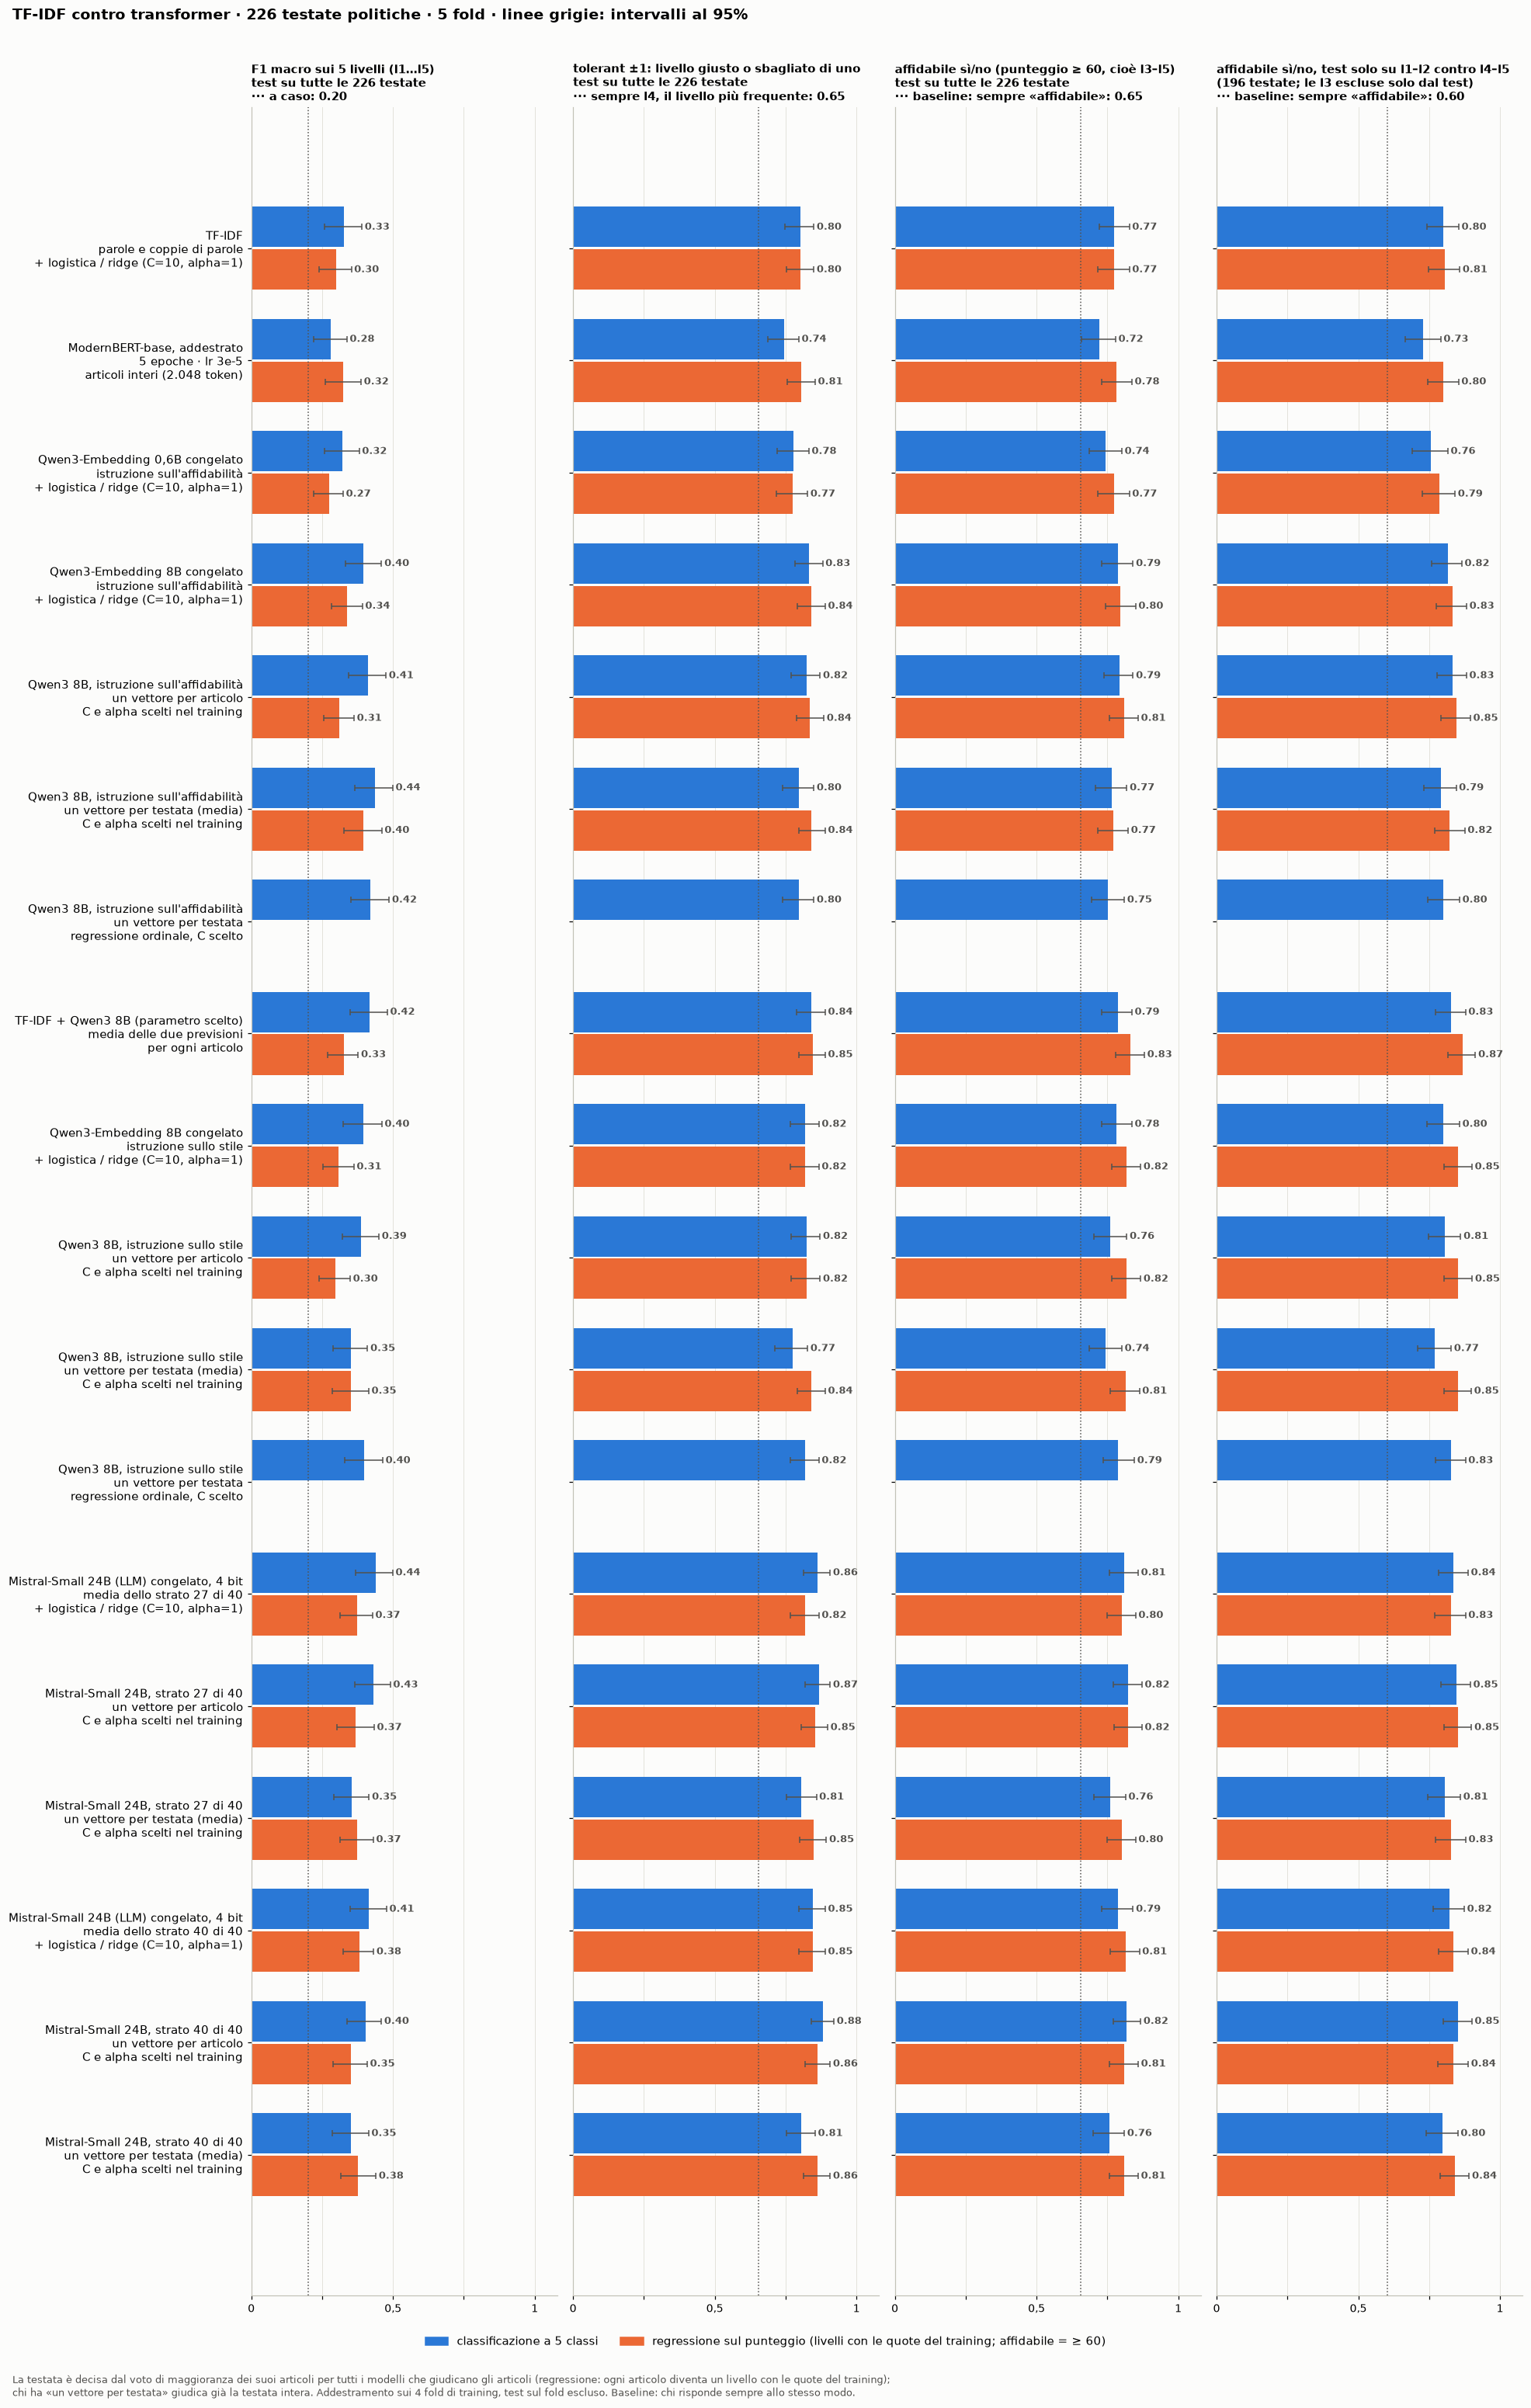

In [10]:
def articoli(f):
    """Le previsioni per articolo salvate da un notebook (se ci sono)."""
    f = Path(f)
    return pd.read_csv(f) if f.exists() else None


mb = [pd.read_csv(f"Results/modernbert/{c}/fold{k}.csv") for c in ["5 classi", "regressione"] for k in range(1, 6)]
PA = {"TF-IDF": tfidf.reset_index(),
      "ModernBERT 2048": pd.concat(mb[:5]).merge(pd.concat(mb[5:])[["article_id", "s_regressione"]], on="article_id"),
      "Embedding Qwen3 0.6B": articoli("Results/embedding/Qwen3-Embedding-0.6B/previsioni_articoli.csv"),
      "8B come nel notebook 4 (C=10, alpha=1)": articoli(Path(EMBEDDING) / "previsioni_articoli.csv"),
      "8B, parametro scelto": pa1, "TF-IDF + 8B (media)": insieme.reset_index(),
      "8B «stile» come nel notebook 4 (C=10, alpha=1)": articoli(Path(ALTRA) / "previsioni_articoli.csv"),
      "8B «stile», parametro scelto": articoli(OUT / "stile_articoli_previsioni.csv")}
for s in STRATI_MISTRAL:
    PA[f"Mistral 24B, strato {s}, come nel notebook 8 (C=10, alpha=1)"] = articoli(Path(MISTRAL.format(s=s)) / "previsioni_articoli.csv")
    PA[f"Mistral 24B, strato {s}, parametro scelto"] = articoli(OUT / f"mistral{s}_articoli_previsioni.csv")
VOTO = {nome: F.testate_voto(PA[nome], t) if PA.get(nome) is not None else v for nome, v in TUTTI.items()}
NOTA_VOTO = ("La testata è decisa dal voto di maggioranza dei suoi articoli per tutti i modelli che giudicano gli articoli (regressione: ogni "
             "articolo diventa un livello con le quote del training);\nchi ha «un vettore per testata» giudica già la testata intera. "
             "Addestramento sui 4 fold di training, test sul fold escluso. Baseline: chi risponde sempre allo stesso modo.")
valori_v, intervalli_v, differenze_v, _ = F.misure_modelli(VOTO)
valori_v.to_csv(OUT / "confronto_voto.csv")
F.grafico_confronto(valori_v, intervalli_v, vero, OUT / "confronto_voto_dettagli.png", dettagli=True, descrizioni=DESCRIZIONI, nota=NOTA_VOTO)

### In numeri, con il voto degli articoli

In [11]:
display(valori_v.round(3))
differenze_v

F1 5 livelli  \
TF-IDF                                             5 classi            0.327   
                                                   regressione         0.300   
ModernBERT 2048                                    5 classi            0.281   
                                                   regressione         0.324   
Embedding Qwen3 0.6B                               5 classi            0.322   
                                                   regressione         0.274   
8B come nel notebook 4 (C=10, alpha=1)             5 classi            0.397   
                                                   regressione         0.338   
8B, parametro scelto                               5 classi            0.411   
                                                   regressione         0.311   
8B, un vettore per testata                         5 classi            0.436   
                                                   regressione         0.397   
8B, un vettore per testata, ordinale               5 classi            0.421   
TF-IDF + 8B (media)                                5 classi            0.417   
                                                   regressione         0.326   
8B «stile» come nel notebook 4 (C=10, alpha=1)     5 classi            0.395   
                                                   regressione         0.308   
8B «stile», parametro scelto                       5 classi            0.388   
                                                   regressione         0.296   
8B «stile», un vettore per testata                 5 classi            0.351   
                                                   regressione         0.353   
8B «stile», un vettore per testata, ordinale       5 classi            0.397   
Mistral 24B, strato 27, come nel notebook 8 (C=... 5 classi            0.438   
                                                   regressione         0.374   
Mistral 24B, strato 27, parametro scelto           5 classi            0.431   
                                                   regressione         0.369   
Mistral 24B, strato 27, un vettore per testata     5 classi            0.355   
                                                   regressione         0.374   
Mistral 24B, strato 40, come nel notebook 8 (C=... 5 classi            0.414   
                                                   regressione         0.380   
Mistral 24B, strato 40, parametro scelto           5 classi            0.403   
                                                   regressione         0.350   
Mistral 24B, strato 40, un vettore per testata     5 classi            0.351   
                                                   regressione         0.377   

                                                                tolerant ±1  \
TF-IDF                                             5 classi           0.801   
                                                   regressione        0.801   
ModernBERT 2048                                    5 classi           0.743   
                                                   regressione        0.805   
Embedding Qwen3 0.6B                               5 classi           0.779   
                                                   regressione        0.774   
8B come nel notebook 4 (C=10, alpha=1)             5 classi           0.832   
                                                   regressione        0.841   
8B, parametro scelto                               5 classi           0.823   
                                                   regressione        0.836   
8B, un vettore per testata                         5 classi           0.796   
                                                   regressione        0.841   
8B, un vettore per testata, ordinale               5 classi           0.796   
TF-IDF + 8B (media)                                5 classi           0.841   
                                                   regressione        0.845   

Δ F1 5 livelli dal TF-IDF  \
ModernBERT 2048                                    5 classi      -0.046 [-0.123; +0.029]   
                                                   regressione   +0.024 [-0.044; +0.095]   
Embedding Qwen3 0.6B                               5 classi      -0.005 [-0.068; +0.062]   
                                                   regressione   -0.026 [-0.095; +0.044]   
8B come nel notebook 4 (C=10, alpha=1)             5 classi      +0.069 [-0.000; +0.141]   
                                                   regressione   +0.038 [-0.032; +0.107]   
8B, parametro scelto                               5 classi      +0.084 [+0.019; +0.154]   
                                                   regressione   +0.011 [-0.054; +0.078]   
8B, un vettore per testata                         5 classi      +0.109 [+0.030; +0.187]   
                                                   regressione   +0.097 [+0.025; +0.168]   
8B, un vettore per testata, ordinale               5 classi      +0.094 [+0.015; +0.174]   
TF-IDF + 8B (media)                                5 classi      +0.090 [+0.037; +0.146]   
                                                   regressione   +0.026 [-0.022; +0.074]   
8B «stile» come nel notebook 4 (C=10, alpha=1)     5 classi      +0.068 [+0.001; +0.134]   
                                                   regressione   +0.008 [-0.049; +0.072]   
8B «stile», parametro scelto                       5 classi      +0.061 [-0.009; +0.135]   
                                                   regressione   -0.003 [-0.063; +0.058]   
8B «stile», un vettore per testata                 5 classi      +0.024 [-0.050; +0.094]   
                                                   regressione   +0.053 [-0.021; +0.122]   
8B «stile», un vettore per testata, ordinale       5 classi      +0.070 [-0.006; +0.143]   
Mistral 24B, strato 27, come nel notebook 8 (C=... 5 classi      +0.111 [+0.040; +0.182]   
                                                   regressione   +0.074 [+0.010; +0.135]   
Mistral 24B, strato 27, parametro scelto           5 classi      +0.103 [+0.033; +0.169]   
                                                   regressione   +0.070 [+0.004; +0.137]   
Mistral 24B, strato 27, un vettore per testata     5 classi      +0.027 [-0.040; +0.095]   
                                                   regressione   +0.075 [+0.012; +0.140]   
Mistral 24B, strato 40, come nel notebook 8 (C=... 5 classi      +0.087 [+0.019; +0.153]   
                                                   regressione   +0.081 [+0.015; +0.149]   
Mistral 24B, strato 40, parametro scelto           5 classi      +0.076 [+0.013; +0.138]   
                                                   regressione   +0.051 [-0.017; +0.123]   
Mistral 24B, strato 40, un vettore per testata     5 classi      +0.024 [-0.051; +0.101]   
                                                   regressione   +0.077 [+0.010; +0.149]   

                                                               Δ binario, tutte dal TF-IDF  
ModernBERT 2048                                    5 classi        -0.053 [-0.111; +0.004]  
                                                   regressione     +0.009 [-0.044; +0.062]  
Embedding Qwen3 0.6B                               5 classi        -0.031 [-0.084; +0.022]  
                                                   regressione     +0.000 [-0.049; +0.053]  
8B come nel notebook 4 (C=10, alpha=1)             5 classi        +0.013 [-0.040; +0.066]  
                                                   regressione     +0.022 [-0.022; +0.066]  
8B, parametro scelto                               5 classi        +0.018 [-0.035; +0.066]  
                                                   regressione     +0.035 [-0.009; +0.080]  
8B, un vettore per testata                         5 classi        -0.009 [-0.058; +0.040]  
                                                   regressione     -0.004 [-0.053; +0.053]  
8B,

## 6. Che cosa viene fuori

- **Scegliere il parametro dentro il training aiuta**: con C e alpha scelti, l'8B batte il TF-IDF sui 5 livelli in modo
  chiaro (F1 0,41 contro 0,33, intervallo della differenza da +0,02 a +0,15). La ridge sceglie quasi sempre alpha =
  1.000 (nel notebook 4 era 1): la regressione sale da 0,31 a 0,34. La C della logistica invece cambia molto tra i fold.
- **Un vettore per testata** è il migliore sui 5 livelli: F1 0,44 (+0,11 sul TF-IDF, da +0,03 a +0,19); l'ordinale non
  aggiunge nulla.
- **TF-IDF + 8B** è il più equilibrato: migliore del TF-IDF su tutte e quattro le misure (tolerant 0,88, affidabile
  sì/no 0,83), quindi le due rappresentazioni vedono cose in parte diverse.
- **L'istruzione sullo stile non aiuta**: stessi valori o un po' meno (un vettore per testata: 0,35 contro 0,44). Spingere
  il vettore lontano dall'argomento toglie segnale, come nelle analisi del tentativo 15 (argomento e geografia pesano).
- **Mistral-Small 24B** (un LLM tre volte più grande, notebook 8) arriva dove arriva l'8B: F1 sui 5 livelli 0,40–0,44
  (strato 27), tolerant fino a 0,88, affidabile sì/no fino a 0,82. Un lettore più grande non sposta i numeri: siamo vicini
  al tetto che le etichette permettono (vedi il tentativo 17, accordo con gli esperti).
- **Il voto degli articoli** (punto 5) cambia poco: per i classificatori è lo stesso; per le regressioni l'F1 sui 5 livelli
  scende un po' (la media dei punteggi tiene più informazione del voto), mentre affidabile sì/no resta uguale o sale di
  poco (TF-IDF + 8B: 0,83).
- Cautela: le varianti sono state confrontate sul test; per il paper va fissata prima una variante e le altre vanno
  presentate come analisi.